In [15]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

SEED = 42
K = 10
DIM = 32
N_NEG = 4
BATCH = 1024
EPOCHS = 60
PATIENCE = 5
LR = 1e-3
WEIGHT_DECAY = 1e-5

D = Path("/content").expanduser()
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
np.random.seed(SEED)
torch.manual_seed(SEED)

train, val, test = (pd.read_csv(D / f"{s}.csv") for s in ["train", "val", "test"])
val_neg, test_neg = np.load(D / "val_neg.npy"), np.load(D / "test_neg.npy")
meta = json.load(open(D / "meta.json"))
n_users, n_items = meta["n_users"], meta["n_items"]
print(device, n_users, n_items, train.shape, val.shape, test.shape, val_neg.shape)

cpu 602 2097 (60419, 7) (7545, 7) (7545, 7) (7545, 99)


In [16]:
def sampled_metrics(S, df, neg, k=K):
    u = df["uid"].to_numpy()
    pos = S[u, df["iid"].to_numpy()]
    negs = S[u[:, None], neg]
    rank = (negs > pos[:, None]).sum(1) + 0.5 * (negs == pos[:, None]).sum(1)
    hit = (rank < k).astype(float)
    return hit.mean(), (hit / np.log2(rank + 2)).mean()


def full_metrics(S, hist, df, k=K):
    S = np.where(hist, -np.inf, S.astype(np.float64) + np.random.default_rng(SEED).random(S.shape) * 1e-9)
    top = np.argsort(-S, axis=1)[:, :k]
    rel = np.zeros((n_users, n_items), dtype=bool)
    rel[df["uid"].to_numpy(), df["iid"].to_numpy()] = True
    gains = np.take_along_axis(rel, top, 1)
    n_rel = rel.sum(1)
    m = n_rel > 0
    disc = 1 / np.log2(np.arange(2, k + 2))
    idcg = np.array([disc[:min(int(n), k)].sum() for n in n_rel])
    recall = (gains.sum(1)[m] / n_rel[m]).mean()
    ndcg = ((gains * disc).sum(1)[m] / idcg[m]).mean()
    return recall, ndcg, len(np.unique(top[m])) / n_items


def evaluate(S, hist, df, neg):
    hr, ndcg_s = sampled_metrics(S, df, neg)
    rec, ndcg, cov = full_metrics(S, hist, df)
    return {"HR@10_100": hr, "NDCG@10_100": ndcg_s, "Recall@10": rec, "NDCG@10": ndcg, "Coverage": cov}


def to_hist(*dfs):
    h = np.zeros((n_users, n_items), dtype=bool)
    for d in dfs:
        h[d["uid"].to_numpy(), d["iid"].to_numpy()] = True
    return h


hist_train = to_hist(train)
hist_trainval = to_hist(train, val)

In [17]:
class GMF(nn.Module):
    def __init__(self, n_users, n_items, dim=32):
        super().__init__()
        self.u = nn.Embedding(n_users, dim)
        self.i = nn.Embedding(n_items, dim)
        nn.init.normal_(self.u.weight, std=0.1)
        nn.init.normal_(self.i.weight, std=0.1)
        self.out = nn.Linear(dim, 1)

    def forward(self, u, i):
        return self.out(self.u(u) * self.i(i)).squeeze(-1)


@torch.no_grad()
def score_all(model):
    model.eval()
    S = (model.u.weight * model.out.weight) @ model.i.weight.T + model.out.bias
    return S.float().cpu().numpy()

In [18]:
tr_u, tr_i = train["uid"].to_numpy(), train["iid"].to_numpy()
pos_keys = np.unique(tr_u.astype(np.int64) * n_items + tr_i)
rng = np.random.default_rng(SEED)


def sample_negatives(n_neg):
    u = np.repeat(tr_u, n_neg)
    neg = rng.integers(0, n_items, len(u))
    while True:
        bad = np.isin(u.astype(np.int64) * n_items + neg, pos_keys)
        if not bad.any():
            return u, neg
        neg[bad] = rng.integers(0, n_items, bad.sum())

In [19]:
model = GMF(n_users, n_items, DIM).to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
loss_fn = nn.BCEWithLogitsLoss()

log, best_ndcg, best_epoch, best_state, bad_epochs = [], -1.0, 0, None, 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    nu, ni = sample_negatives(N_NEG)
    U = torch.from_numpy(np.concatenate([tr_u, nu])).long().to(device)
    I = torch.from_numpy(np.concatenate([tr_i, ni])).long().to(device)
    Y = torch.cat([torch.ones(len(tr_u)), torch.zeros(len(nu))]).to(device)
    perm = torch.randperm(len(U)).to(device)

    total = 0.0
    for s in range(0, len(U), BATCH):
        idx = perm[s:s + BATCH]
        opt.zero_grad()
        loss = loss_fn(model(U[idx], I[idx]), Y[idx])
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)

    m = evaluate(score_all(model), hist_train, val, val_neg)
    log.append({"epoch": epoch, "loss": total / len(U), **m})
    print(f"{epoch:2d} | loss {total / len(U):.4f} | HR@10 {m['HR@10_100']:.4f} | "
          f"NDCG@10 {m['NDCG@10_100']:.4f} | full NDCG@10 {m['NDCG@10']:.4f}")

    if m["NDCG@10_100"] > best_ndcg:
        best_ndcg, best_epoch, bad_epochs = m["NDCG@10_100"], epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            break

model.load_state_dict(best_state)
print(f"Лучшая эпоха: {best_epoch}, val NDCG@10 (100 кандидатов) = {best_ndcg:.4f}")

 1 | loss 0.6811 | HR@10 0.2680 | NDCG@10 0.1409 | full NDCG@10 0.0459
 2 | loss 0.5425 | HR@10 0.3268 | NDCG@10 0.1746 | full NDCG@10 0.0597
 3 | loss 0.4249 | HR@10 0.3360 | NDCG@10 0.1794 | full NDCG@10 0.0601
 4 | loss 0.3974 | HR@10 0.3690 | NDCG@10 0.1941 | full NDCG@10 0.0640
 5 | loss 0.3707 | HR@10 0.3830 | NDCG@10 0.2025 | full NDCG@10 0.0684
 6 | loss 0.3546 | HR@10 0.3991 | NDCG@10 0.2134 | full NDCG@10 0.0776
 7 | loss 0.3377 | HR@10 0.4144 | NDCG@10 0.2241 | full NDCG@10 0.0789
 8 | loss 0.3230 | HR@10 0.4284 | NDCG@10 0.2319 | full NDCG@10 0.0766
 9 | loss 0.3098 | HR@10 0.4437 | NDCG@10 0.2410 | full NDCG@10 0.0786
10 | loss 0.2986 | HR@10 0.4494 | NDCG@10 0.2441 | full NDCG@10 0.0806
11 | loss 0.2876 | HR@10 0.4575 | NDCG@10 0.2484 | full NDCG@10 0.0806
12 | loss 0.2791 | HR@10 0.4635 | NDCG@10 0.2500 | full NDCG@10 0.0806
13 | loss 0.2694 | HR@10 0.4616 | NDCG@10 0.2494 | full NDCG@10 0.0807
14 | loss 0.2608 | HR@10 0.4624 | NDCG@10 0.2492 | full NDCG@10 0.0812
15 | l

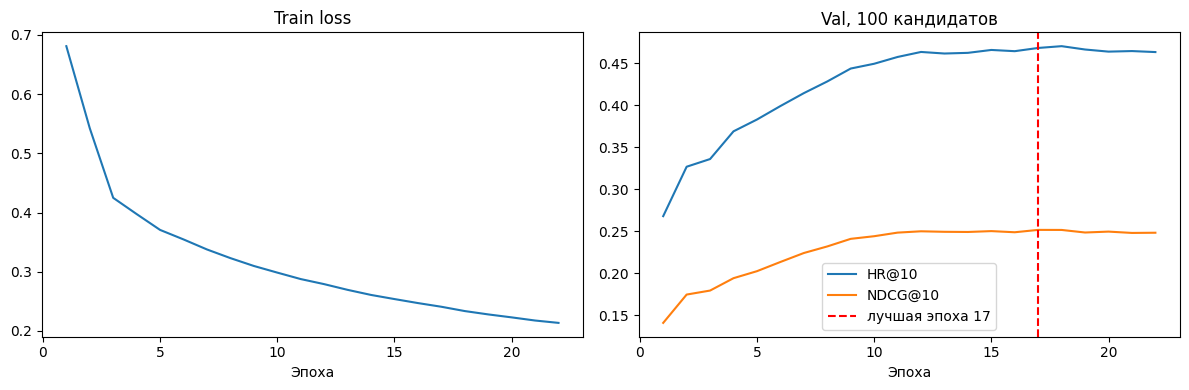

In [20]:
log_df = pd.DataFrame(log)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(log_df["epoch"], log_df["loss"])
ax[0].set(title="Train loss", xlabel="Эпоха")
ax[1].plot(log_df["epoch"], log_df["HR@10_100"], label="HR@10")
ax[1].plot(log_df["epoch"], log_df["NDCG@10_100"], label="NDCG@10")
ax[1].axvline(best_epoch, color="red", ls="--", label=f"лучшая эпоха {best_epoch}")
ax[1].set(title="Val, 100 кандидатов", xlabel="Эпоха")
ax[1].legend()
plt.tight_layout()
plt.show()

In [21]:
S_gmf = score_all(model)
S_pop = np.tile(hist_train.sum(0).astype(np.float64), (n_users, 1))

res = pd.DataFrame({
    "GMF val": evaluate(S_gmf, hist_train, val, val_neg),
    "Popularity val": evaluate(S_pop, hist_train, val, val_neg),
    "GMF test": evaluate(S_gmf, hist_trainval, test, test_neg),
    "Popularity test": evaluate(S_pop, hist_trainval, test, test_neg),
}).T.round(4)
res

,HR@10_100,NDCG@10_100,Recall@10,NDCG@10,Coverage
GMF val,0.4683,0.2516,0.0722,0.0847,0.2737
Popularity val,0.3229,0.1702,0.0510,0.0617,0.0410
GMF test,0.3902,0.2055,0.0607,0.0662,0.2833
Popularity test,0.2847,0.1451,0.0387,0.0513,0.0434


In [22]:

!pip install mlflow
import mlflow

mlflow.set_tracking_uri("http://0.0.0.0:5000")
mlflow.set_experiment("Сollaborative_Filtering")

METRICS = {
    "HR@10_100": f"hr_N_{K}_100cand",
    "NDCG@10_100": f"ndcg_N_{K}_100cand",
    "Recall@10": f"recall_N_{K}",
    "NDCG@10": f"ndcg_N_{K}",
    "Coverage": "coverage",
}

final = {
    "val": evaluate(S_gmf, hist_train, val, val_neg),
    "test": evaluate(S_gmf, hist_trainval, test, test_neg),
}

with mlflow.start_run(run_name="NCF_GMF"):
    mlflow.log_param("model_type", "GMF")
    mlflow.log_params({
        "top_k": K, "n_neg_train": N_NEG, "n_neg_eval": meta["n_neg_eval"],
        "batch_size": BATCH, "max_epochs": EPOCHS, "patience": PATIENCE,
        "lr": LR, "weight_decay": WEIGHT_DECAY, "seed": SEED,
        "gmf_dim": model.u.embedding_dim,
        "n_params": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch, "epochs_run": len(log_df),
        "device": device, "test_fit_on": "train",
    })

    for _, r in log_df.iterrows():
        step = int(r["epoch"])
        mlflow.log_metric("curve_train_loss", float(r["loss"]), step=step)
        for col, key in METRICS.items():
            mlflow.log_metric(f"curve_val_{key}", float(r[col]), step=step)

    for split, m in final.items():
        for col, key in METRICS.items():
            mlflow.log_metric(f"{split}_{key}", float(m[col]))

    mlflow.log_figure(fig, "training_curves.png")
    mlflow.log_text(log_df.to_csv(index=False), "training_log.csv")

KeyboardInterrupt: 